# LLM Confidence scores analysis

This notebook explores methods for estimating confidence in large language models (LLMs) applied to clinical information extraction tasks, with a particular focus on token-level probabilities. Rather than treating model predictions as binary outcomes, we assess the model's confidence throughout the text generation process.

The backbone model used in this study is **LLaMA 3.3 70B Instruct**, quantized to 8-bit precision. It was selected for its computational efficiency and accessibility, while still providing access to token-level probabilities.

This study demonstrates how confidence estimation methods can help identify when a model's outputs can be considered reliable.

In [24]:
import numpy as np
import pandas as pd
import os
import re
import math
import json
import time
from sklearn.metrics import roc_auc_score
from sklearn.cluster import KMeans, DBSCAN, MiniBatchKMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, average_precision_score
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable   
from IPython.display import HTML, display
from scipy import stats
from scipy.signal import find_peaks
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

## Confidence estimation methods

We estimate LLM confidence using:

- **Sequence Probability (SP)** : measures the joint probability of all tokens in the generated response.
- **Length-Normalized Sequence Probability (LNSP)** : computed as the geometric mean of the token probabilities.
- **Minimum Token Probability (MTP)** : uses the lowest token probability within the generated sequence as a confidence score.
- **Probability Margin (PM)** : measures the difference between the probabilities of the most likely and second most likely tokens at each position.
- **Average Top-K Token Negentropy (ATN@K)** : computes the entropy of the top-K token distribution at each generation step and transforms it into a confidence score by computing the average normalized token negentropy across all positions.
- **Minimum Top-K Token Negentropy (MTN@K)** : uses the minimum normalized token negentropy across all token positions as the confidence score.

## Confidence evaluation metrics

To assess the quality of confidence estimates, several complementary metrics were used:

- **Accuracy** : measures prediction correctness
- **AUROC (Area Under the Receiver Operating Characteristic Curve)** : measures the ability of confidence scores to distinguish between correct and incorrect responses (we use incorrect responses as positives).
- **AUPRC (Area Under the Precision–Recall Curve)** : evaluates the ability of an uncertainty score to distinguish between correct and incorrect responses using the precision–recall curve (for AUPRC-P we use correct responses as positives, for AUPRC-P we use incorrect responses as positives).
- **AUARC (Area Under the Accuracy–Rejection Curve)** : evaluates the ability of an uncertainty estimation method to identify correct predictions for retention while rejecting uncertain predictions.
- **Expected Calibration Error (ECE)** : assesses the alignment between a model's estimated confidence and its actual accuracy.
- **Brier score**: evaluates both accuracy and calibration; lower values are better.
- **Risk–coverage (AURC)**: assesses selective prediction by measuring the trade-off between abstention and risk.

In [32]:
def create_df(model="llama3.3:70b-instruct-q8_0_32k"):

    file_path = "path_to_results_folder/"
    
    disambiguation_file_path = file_path + "correctness_" + model + "_clinical_sense_disambiguation.xlsx"
    coreference_file_path = file_path+ "correctness_" + model + "_coreference_resolution.xlsx"
    status_file_path = file_path + "correctness_" + model + "_medication_status_extraction.xlsx"
    attribute_file_path = file_path+ "correctness_" + model + "_medication_attribute_extraction.xlsx"
    
    xls_disambiguation = pd.ExcelFile(disambiguation_file_path)
    xls_coreference = pd.ExcelFile(coreference_file_path)
    xls_status = pd.ExcelFile(status_file_path)
    xls_attribute = pd.ExcelFile(attribute_file_path)
    
    df_disambiguation = pd.read_excel(xls_disambiguation, 'correctness')
    df_coreference = pd.read_excel(xls_coreference, 'correctness')
    df_status = pd.read_excel(xls_status, 'correctness')
    df_attribute = pd.read_excel(xls_attribute, 'correctness')

    df_disambiguation = df_disambiguation.dropna(subset=["perplexity", "SP", "LNSP", "MTP", "PM", "ATN@5", "MTN@5"])
    df_coreference = df_coreference.dropna(subset=["perplexity", "SP", "LNSP", "MTP", "PM", "ATN@5", "MTN@5"])
    df_status = df_status.dropna(subset=["perplexity", "SP", "LNSP", "MTP", "PM", "ATN@5", "MTN@5"])
    df_attribute = df_attribute.dropna(subset=["perplexity", "SP", "LNSP", "MTP", "PM", "ATN@5", "MTN@5"])

    return df_disambiguation, df_coreference, df_status, df_attribute

In [26]:
# brier score 
def brier(conf, labels):
    conf=np.asarray(conf, float)
    labels=np.asarray(labels, float)
    return float(np.mean((conf - labels)**2))

# expected calibration error
def ece(conf, labels, n_bins=10):
    conf=np.asarray(conf, float); labels=np.asarray(labels, float)
    bins=np.linspace(0.0, 1.0, n_bins+1)
    e=0.0; N=len(conf)
    for i in range(n_bins):
        if i == 0:
            mask=(conf >= bins[i]) & (conf <= bins[i+1])
        else:
            mask=(conf > bins[i]) & (conf <= bins[i+1])
        if not np.any(mask): 
            continue
        acc=float(np.mean(labels[mask]))
        avg_c=float(np.mean(conf[mask]))
        e += (np.sum(mask)/N) * abs(acc - avg_c)
    return float(e)

def compute_ece(
    uncertainties: np.ndarray,
    correctness: np.ndarray,
    num_bins: int = 10,
) -> float:
    """
    Compute Expected Calibration Error.
    
    Measures how well uncertainty aligns with actual error rate.
    Lower ECE = better calibration.
    
    Args:
        uncertainties: Array of uncertainty scores (should be probabilities 0-1)
        correctness: Binary array (1 = correct, 0 = incorrect)
        num_bins: Number of bins for calibration
    
    Returns:
        ECE score (0 = perfect calibration)
    """
    # Convert uncertainties to confidence (1 - uncertainty)
    # Normalize if needed
    u_min, u_max = uncertainties.min(), uncertainties.max()
    if u_max > u_min:
        normalized_u = (uncertainties - u_min) / (u_max - u_min)
    else:
        normalized_u = np.zeros_like(uncertainties)
    
    # Confidence = 1 - normalized_uncertainty
    confidences = 1 - normalized_u
    
    # Bin confidences
    bin_boundaries = np.linspace(0, 1, num_bins + 1)
    ece = 0.0
    total_samples = len(confidences)
    
    for i in range(num_bins):
        bin_lower = bin_boundaries[i]
        bin_upper = bin_boundaries[i + 1]
        
        # Find samples in this bin
        if i == num_bins - 1:
            in_bin = (confidences >= bin_lower) & (confidences <= bin_upper)
        else:
            in_bin = (confidences >= bin_lower) & (confidences < bin_upper)
        
        bin_size = np.sum(in_bin)
        
        if bin_size > 0:
            # Average confidence in bin
            avg_confidence = np.mean(confidences[in_bin])
            
            # Actual accuracy in bin
            accuracy = np.mean(correctness[in_bin])
            
            # Contribution to ECE
            ece += (bin_size / total_samples) * np.abs(accuracy - avg_confidence)
    
    return ece

def calculate_aurc(confidences, correctness, num_points: int = 100) -> float:
    """
    Calculate Area Under the Risk-Coverage curve (AURC).
    
    The Risk-Coverage curve shows the relationship between the error rate (risk)
    and the fraction of samples the model makes predictions for (coverage).
    Lower AURC values indicate better selective prediction performance.
    
    Args:
        confidences: List of confidence scores
        correctness: List of correctness indicators (0 or 1)
        num_points: Number of points to evaluate on the curve
        
    Returns:
        Area under the risk-coverage curve
    """
    confidences = np.asarray(confidences, float)
    correctness = np.asarray(correctness, float)
    
    # Sort by confidence in descending order
    sorted_indices = np.argsort(confidences)[::-1]
    sorted_correctness = correctness[sorted_indices]
    
    coverages = np.linspace(0.01, 1.0, num_points)  # Avoid division by zero at 0
    risks = []
    
    for coverage in coverages:
        n_samples = int(len(correctness) * coverage)
        if n_samples == 0:
            risks.append(0.0)
            continue
            
        # Calculate error rate for current coverage
        errors = 1 - sorted_correctness[:n_samples]
        risk = np.mean(errors)
        risks.append(risk)
    
    # Calculate area under the curve using trapezoidal rule
    aurc = np.trapz(risks, coverages)
    return float(aurc)

def AUARC(labels, confidences):
    # An accuracy rejection curve (ARC) is a function representating the accuracy of a classifier \
    # as a function of its reject rate. 
    # An ARC is therefore produced by plotting the accuracy of a classifier against its reject rate, from [0,1].
    # All ARCs have an accuracy of 100% for a rejection rate of 100%
    # Source:
    #     https://github.com/shuoli90/Rank-Calibration/blob/main/metrics/calibration.py 
    rejection_rate = np.arange(0, 1, 0.01)
    if type(confidences) is not np.ndarray:
        confidences = np.array(confidences)
    if type(labels) is not np.ndarray:
        labels = np.array(labels)
    arcs = []
    for rate in rejection_rate:
        labels_tmp = labels[confidences > np.quantile(confidences, rate)]
        if len(labels_tmp) == 0:
            arc = 1.0
        else:
            # reject rate portion of the data
            arc = np.mean(labels_tmp)
        arcs.append(arc)
    return np.trapz(arcs, rejection_rate)

def compute_prr(y_true, confidence):
    """
    compute Prediction Rejection Ratio (PRR) = AUCPR_unc / AUCPR_oracle
      - AUCPR_unc = average_precision_score(y_true, confidence)
      - AUCPR_oracle = average_precision_score(y_true, y_true)  
    """
    
    aucpr_unc = average_precision_score(y_true, confidence)
    aucpr_oracle = average_precision_score(y_true, y_true)  
    

    if aucpr_oracle == 0:
        return np.nan
    else:
        return aucpr_unc / aucpr_oracle


def calculate_metrics(df, method='SP', label='correctness'):
    mask=df[method].notnull()
    conf=df.loc[mask, method].astype(float).values
    labels=df.loc[mask, label].astype(float).values
    uncert=1.0 - conf

    if len(conf) >= 2:
        acc=float(labels.mean())
        br=brier(conf, labels)
        # ec=ece(conf, labels, n_bins=10)
        ec=compute_ece(1-conf, labels, num_bins=10)
        aurc = calculate_aurc(conf, labels)
        auarc = AUARC(labels, conf)
        auprc_p = average_precision_score(labels, conf)
        # prr = compute_prr(labels, conf)
        y_err=1.0-labels
        auprc_n = average_precision_score(y_err, uncert)
        auc=float(roc_auc_score(y_err, uncert)) if len(np.unique(y_err)) > 1 else float("nan")
    else:
        acc=br=ec=auc=float("nan")

    metrics=dict(accuracy=acc, brier=br, ece=ec, auroc=auc, auprc_p=auprc_p, auprc_n=auprc_n, aurc=aurc, auarc=auarc)

    return metrics

In [27]:
# histogram (distplot) plot by feature vs correctness
def plot_dist_by_correct(df, model, task, feature_col="SP", label_col="correctness", bins=20, save_dir="visualization", save=False):
    d = df[[feature_col, label_col]].copy()
    d[feature_col] = pd.to_numeric(d[feature_col], errors="coerce")
    d[label_col] = pd.to_numeric(d[label_col], errors="coerce")
    d = d.dropna()

    if len(d) == 0:
        print("No data to plot")
        return

    ok = d[label_col].astype(int) == 1
    vals_ok = d.loc[ok, feature_col]
    vals_ng = d.loc[~ok, feature_col]

    fig1, ax1 = plt.subplots(figsize=(6, 5))

    sns.distplot(
        vals_ok,
        bins=bins,
        kde=True,
        hist=False,
        label="Correct",
        ax=ax1,
    )

    sns.distplot(
        vals_ng,
        bins=bins,
        kde=True,
        hist=False,
        label="Incorrect",
        ax=ax1,
    )

    ax1.set_xlabel("Score")
    ax1.set_ylabel("Density")
    ax1.set_title(f"{feature_col} by correctness")
    ax1.legend()
    ax1.grid(False)

    plt.tight_layout()

    if save:
        save_dir = save_dir + f"/{model}/"
        os.makedirs(save_dir, exist_ok=True)
        fig1.savefig(
            os.path.join(save_dir, f"{task}_{feature_col}_vs_correctness_distplot_{model}.jpeg"),
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()

In [28]:
def scatter_features_by_correct(df, model_name, task,
                                features=[("verbal_confidence","LNSP"),("verbal_confidence","PM"),("verbal_confidence","ATN@5"),("verbal_confidence","MTN@5")], 
                                label_col="correctness", title="Uncertainty feature scatter", save=False,save_path=None):
    needed = [label_col] + list(dict.fromkeys([col for pair in features for col in pair]))
    d = df[needed].dropna().copy()
    if d.empty:
        print("No data available for scatter plot")
        return
    d[label_col] = d[label_col].astype(int)
    palette = {0: "red", 1: "blue"}
    n = len(features)
    fig, axes = plt.subplots(1, n, figsize=(6*n, 5))
    if n == 1:
        axes = [axes]

    for ax, (x, y) in zip(axes, features):
        sns.scatterplot(data=d, x=x, y=y, hue=label_col, palette=palette, alpha=0.6, s=40, ax=ax)
        ax.set_xlabel(x)
        ax.set_ylabel(y)
        ax.set_title(f"{x} vs {y}")

    plt.suptitle(title)
    plt.tight_layout()

    if save:
        if save_path is None:
            save_path = f"visualization/{model_name}/{task}_{title}_{model_name}.jpeg"
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, dpi=200)
        print(f"Figure saved to {save_path}")
    plt.show()

In [29]:
def compute_selective_accuracy(uncertainties: np.ndarray, correctness: np.ndarray, coverage: float = 0.8,) -> float:
    """
    Compute accuracy when selecting the most confident predictions.
    
    Args:
        uncertainties: Array of uncertainty scores
        correctness: Binary array
        coverage: Fraction of predictions to keep (0 to 1)
    
    Returns:
        Accuracy on selected subset
    """
    n = len(uncertainties)
    n_select = int(n * coverage)
    
    if n_select == 0:
        return 0.0
    
    # Select samples with lowest uncertainty
    sorted_indices = np.argsort(uncertainties)
    selected_indices = sorted_indices[:n_select]
    
    # Compute accuracy on selected
    selected_correct = correctness[selected_indices]
    
    return np.mean(selected_correct)
    
def plot_selective_accuracy(df, model, task, label_col="correctness", title="Selective Accuracy: Accuracy vs Coverage Trade-off", save_path: str = None):
    """Plot selective accuracy curves for all methods."""

    labels = df[label_col].astype(float).values
    methods = ["SP", "LNSP", "MTP", "PM", "ATN@5", "MTN@5"]
    
    coverage_levels = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    
    plt.figure(figsize=(10, 6))
    
    colors = plt.cm.tab10(np.linspace(0, 1, len(methods)))
    
    for i, method in enumerate(methods):
        scores = pd.to_numeric(df[method], errors="coerce").astype(float).values
        uncertainties = -scores if method != "perplexity" else scores
        accuracies = [
            compute_selective_accuracy(uncertainties, labels, c)
            for c in coverage_levels
        ]
        plt.plot(coverage_levels, accuracies, 'o-', label=method, color=colors[i], linewidth=2)
    
    plt.xlabel("Coverage (fraction of predictions to keep)")
    plt.ylabel("Accuracy on keeped predictions")
    plt.title(title)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.xlim(0.45, 1.05)
    
    plt.tight_layout()
    
    if save_path is None:
            save_path = f"visualization/{model}/{task}_elective Accuracy_{model}.jpeg"
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=200)
    plt.show()

In [30]:
# models = ["gemma3:27b-it-q8_0_32k", "gemma4:e4b-it-q8_0", "qwen3:32b-q8_0_32k", "qwen2.5:72b-instruct-q8_0_32k", "llama3.3:70b-instruct-q8_0_32k"]
model = "llama3.3:70b-instruct-q8_0_32k"
df_disambiguation, df_coreference, df_status, df_attribute = create_df(model)

print(df_disambiguation.shape)
print(df_coreference.shape)
print(df_status.shape)
print(df_attribute.shape)

(27209, 13)
(105, 14)
(315, 13)
(105, 12)


In [31]:
features=["SP", "LNSP", "MTP", "PM", "ATN@5", "MTN@5"]
# tasks = ["clinical_sense_disambiguation", "coreference_resolution", "medication_status_extraction", "medication_attribute_extraction"]

summary = {}
################## Choose the task and the coresponding dataframe for analysis
task  = "clinical_sense_disambiguation"
data = df_disambiguation.copy()

for f in features:
    print(f"{'='*62}", f)
    metrics=calculate_metrics(data, method=f)
    summary[f] = metrics
    
    print("Metric summary based on confidence -")
    
    for i in metrics.keys():
        print(i,'score \t:',metrics[i])

################## For Saving Results
# df_metrics = pd.DataFrame.from_dict(summary, orient='index', columns=['accuracy', 'brier', 'ece', 'auroc', 'auprc_p', 'auprc_n', 'aurc', 'auarc'])
# save_path = f"visualization/{model}/{task}_metric_summary_{model}.csv"
# os.makedirs(os.path.dirname(save_path), exist_ok=True)
# df_metrics.to_csv(save_path, index=False, header=True)

============================================================== SP
Metric summary based on confidence -
accuracy score 	: 0.8882355103090889
brier score 	: 0.10388605019030042
ece score 	: 0.09069191070734306
auroc score 	: 0.7960303239049769
auprc_p score 	: 0.9646120103798645
auprc_n score 	: 0.30088272600845556
aurc score 	: 0.038619363097287036
auarc score 	: 0.9513790761842842
============================================================== LNSP
Metric summary based on confidence -
accuracy score 	: 0.8882355103090889
brier score 	: 0.10692819616551111
ece score 	: 0.10023415167682577
auroc score 	: 0.772926417684996
auprc_p score 	: 0.9607687429607245
auprc_n score 	: 0.25463272042147184
aurc score 	: 0.04209337565196738
auarc score 	: 0.9479075665730747
============================================================== MTP
Metric summary based on confidence -
accuracy score 	: 0.8882355103090889
brier score 	: 0.10399565845972651
ece score 	: 0.09105324208369164
auroc score 	: 0.794845

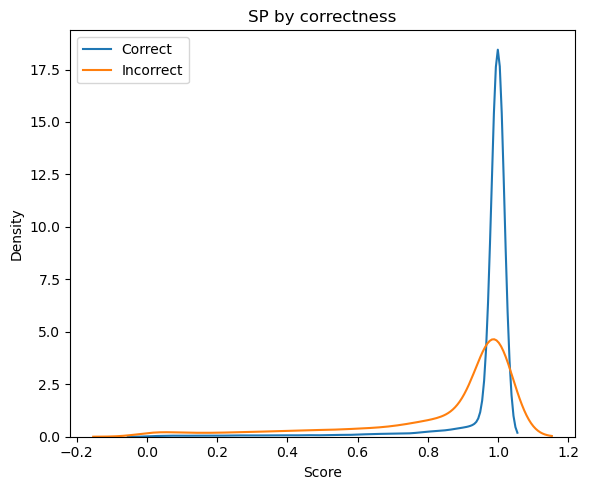

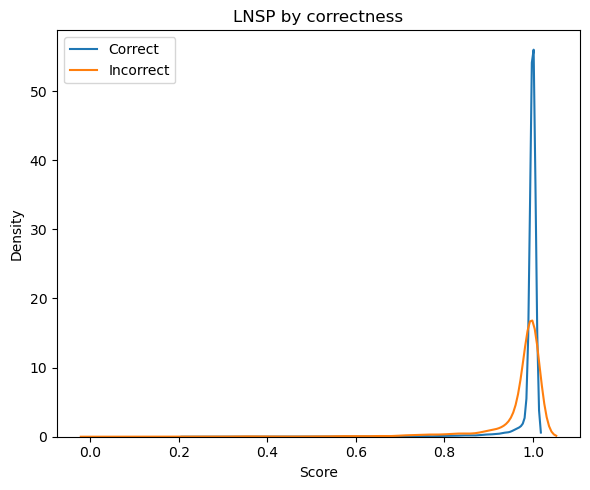

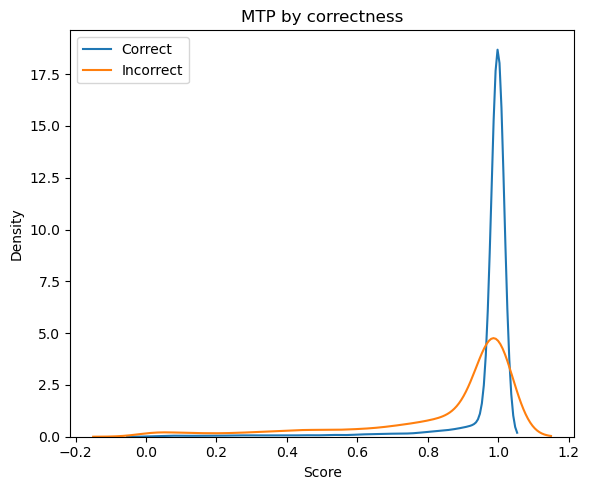

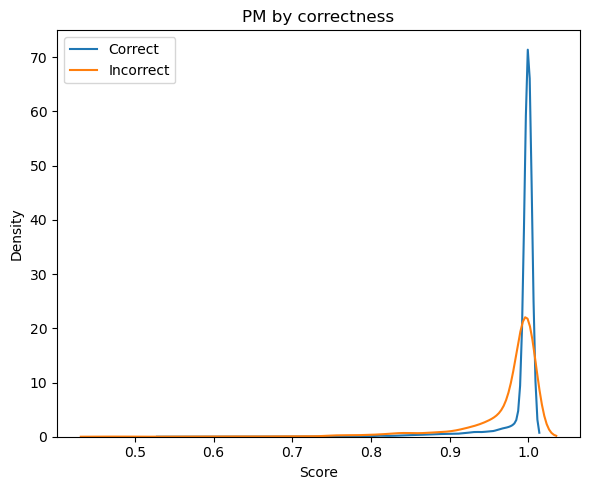

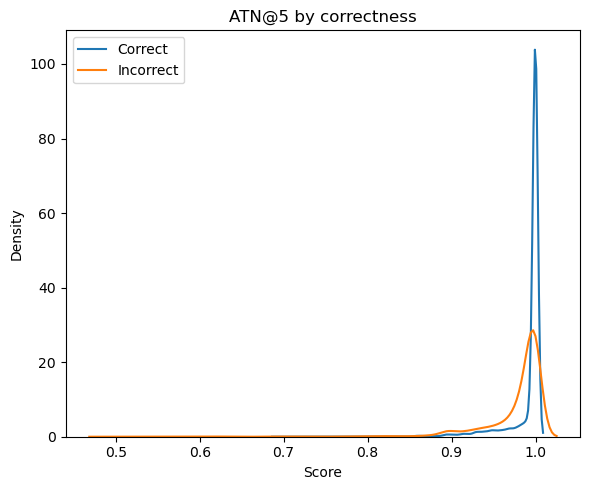

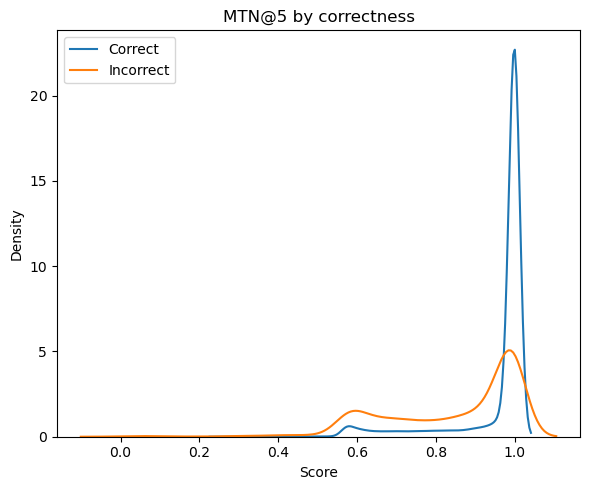

In [17]:
features=["SP", "LNSP", "MTP", "PM", "ATN@5", "MTN@5"]
for f in features:
    plot_dist_by_correct(data, model, task, feature_col=f)

Figure saved to visualization/llama3.3:70b-instruct-q8_0_32k/clinical_sense_disambiguation_Uncertainty feature scatter_llama3.3:70b-instruct-q8_0_32k.jpeg


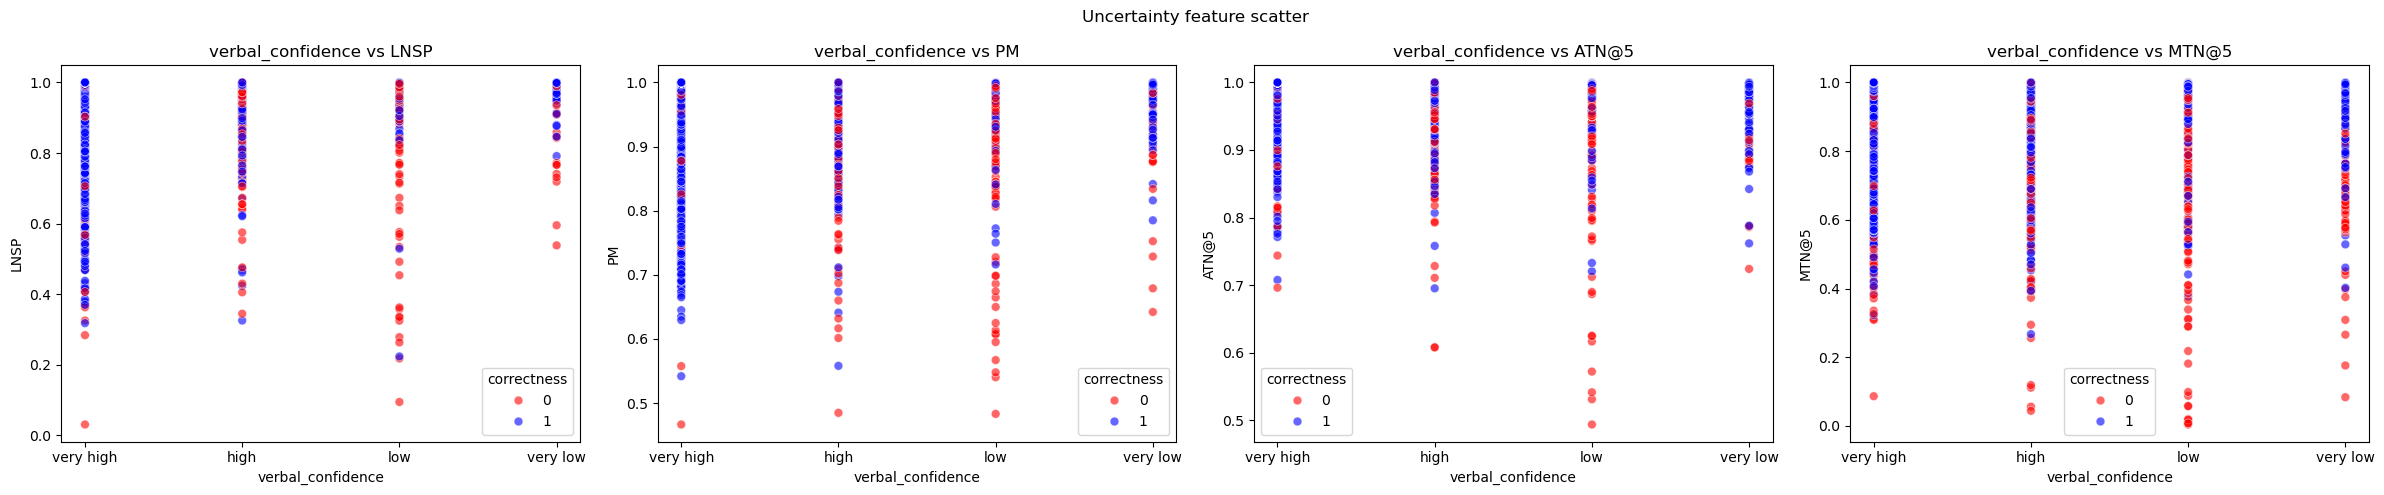

In [18]:
scatter_features_by_correct(data, model, task, title="Uncertainty feature scatter")

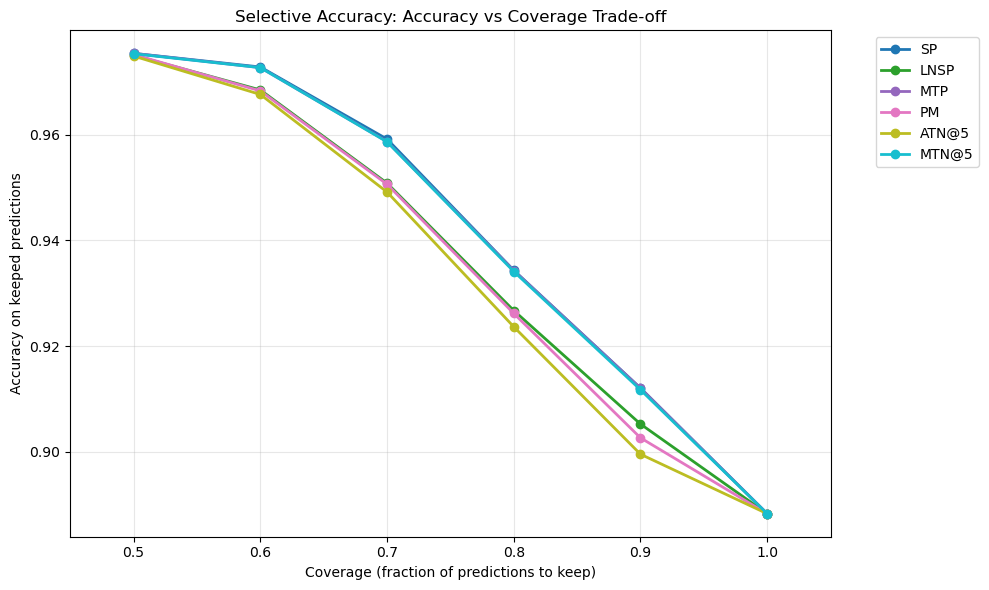

In [19]:
plot_selective_accuracy(data, model, task)

In [20]:
def compute_selective_accuracy_analysis(df, model, label_col="correctness"):
    """Analyze selective accuracy at different coverage levels."""
    
    labels = df[label_col].astype(float).values
    methods = ["perplexity", "SP", "LNSP", "MTP", "PM", "ATN@5", "MTN@5"]
    
    coverage_levels = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    
    analysis = {}
    for coverage in coverage_levels:
        values = []
        for m in methods :
            scores = pd.to_numeric(df[m], errors="coerce").astype(float).values
            uncertainties = -scores if m != "perplexity" else scores
            values.append((m, compute_selective_accuracy(uncertainties, labels, coverage)))
        values.sort(key=lambda x: x[1], reverse=True)
        analysis[coverage] = {
            "best": values[0][0],
            "worst": values[-1][0],
            "ranking": [(m, v, i+1) for i, (m, v) in enumerate(values)],
            # "ranking": values,
        }
    
    return analysis

def compute_method_rankings(method_metrics):
    """Rank methods by each metric."""
    methods = list(method_metrics.keys())
    
    # Metrics where higher is better
    higher_better = ["auroc", "auprc_p", "auprc_n",  "auarc"]
    # Metrics where lower is better
    lower_better = ["ece"]
    
    rankings = {}
    
    for metric in ["auroc", "auprc_p", "auprc_n",  "auarc", "ece"]:
        values = [(m, method_metrics[m].get(metric, 0)) for m in methods]
        
        if metric in higher_better:
            values.sort(key=lambda x: x[1], reverse=True)
        else:
            values.sort(key=lambda x: x[1])
        
        rankings[metric] = {
            "best": values[0][0],
            "worst": values[-1][0],
            "ranking": [(m, v, i+1) for i, (m, v) in enumerate(values)],
        }
    
    return rankings

In [21]:
result = compute_selective_accuracy_analysis(data, model)
print(result)

In [22]:
result = compute_method_rankings(summary)
print(result)